# Домашнее задание 1. Top-10 рекомендации: Goodreads Comics & Graphic

В этом ноутбуке рассматриваются модели ItemKNN, iALS, EASE, FM с метапризнаками, timeSVD++ (плюс baseline Popularity) на датасете Goodreads.

Запуск:

```bash
python3.12 -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 experiments.ipynb
```

- Данные скачиваются автоматически в `data/`
- Подобранные гиперпараметры кэшируются в `results/best_params.json`
- Зафиксирован сид `SEED = 42` для воспроизводимости

In [1]:
import json
import sys
import warnings
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sys.path.insert(0, ".")
import common
import dataset
import tuning
from models import EASE, FM, IALS, ItemKNN, Popularity, TimeSVDpp

SEED = common.SEED
common.set_seed(SEED)
sns.set_theme(style="whitegrid")

CACHE = Path("results/best_params.json")
CACHE.parent.mkdir(exist_ok=True)

## 1. Данные

Датасет: Goodreads Comics & Graphic (UCSD Book Graph), https://cseweb.ucsd.edu/~jmcauley/datasets/goodreads.html

Исходный объем: 7 347 630 записей «пользователь положил книгу на полку» (342 415 пользователей), 89 411 книг. Рекомендуем 10 книг (комиксов и графических романов) для пользователя Goodreads.

Используемые поля:

- Взаимодействия: `user_id`, `book_id`, `rating` (0 - книга на полке без оценки, 1-5 - оценка), `date_updated` (время последнего изменения записи, используется как время оценки)
- Книги (метапризнаки FM): `authors`, `publication_year`, `num_pages`, `format`, `language_code`, `publisher`, `is_ebook`, `series`, `description`
- Не используются: агрегаты по всему периоду (`average_rating`, `ratings_count`, `popular_shelves`, `similar_books`), так как они включают тестовое окно (утечка из будущего), а также остальные служебные поля

Как получена выборка:

1. Оставляем оцененные записи (`rating > 0`)
2. 10-core: итеративно удаляем пользователей и книги, у которых меньше 10 взаимодействий, пока такие остаются
3. Случайно берем 16 000 пользователей (seed 42), чтобы матрица EASE поместилась в память
4. Снова core: >= 10 оценок на пользователя и >= 20 на книгу

In [2]:
if not (dataset.PROCESSED_DIR / "books.parquet").exists():
    dataset.download()
    dataset.prepare()

inter, books = dataset.load_processed()
print("Итоговый объем датасета", end="\n\n")
print(f"Взаимодействий: {len(inter)}", f"Пользователей: {inter.user_id.nunique()}", f"Книг: {inter.book_id.nunique()}", sep="\n")

Итоговый объем датасета

Взаимодействий: 699198
Пользователей: 14238
Книг: 8493


## 2. EDA

In [3]:
n_users, n_items = inter.user_id.nunique(), inter.book_id.nunique()
print(
    f"Плотность матрицы: {len(inter) / (n_users * n_items):.3%}",
    f"Доля оценок >= 4: {(inter.rating >= 4).mean():.1%}",
    f"Дубликатов пар: {inter.duplicated(['user_id', 'book_id']).sum()}",
    f"Пропусков: {inter.isna().sum().sum()}",
    sep="\n",
)

Плотность матрицы: 0.578%
Доля оценок >= 4: 75.6%
Дубликатов пар: 0
Пропусков: 0


Оценок на пользователя, медиана: 24
Оценок на пользователя, максимум: 1703
Доля взаимодействий у топ-1% книг: 14.7%


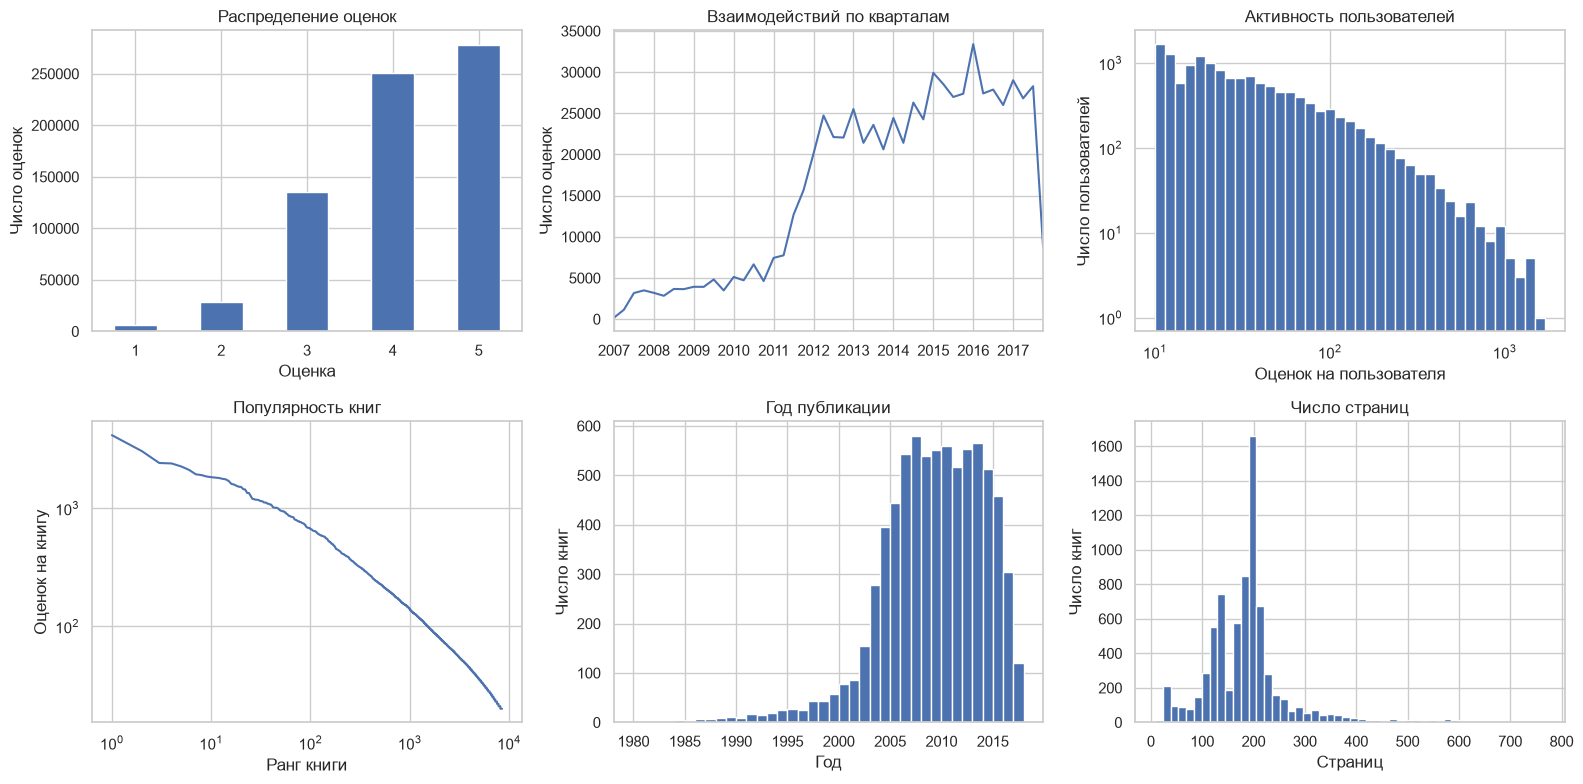

In [4]:
user_counts = inter.groupby("user_id").size()
item_counts = inter.groupby("book_id").size().sort_values(ascending=False)
top_share = item_counts.iloc[: len(item_counts) // 100].sum() / item_counts.sum()
print(
    f"Оценок на пользователя, медиана: {user_counts.median():.0f}",
    f"Оценок на пользователя, максимум: {user_counts.max()}",
    f"Доля взаимодействий у топ-1% книг: {top_share:.1%}",
    sep="\n",
)

years = books.publication_year[books.publication_year >= 1980]
pages = books.num_pages[(books.num_pages > 0) & (books.num_pages < 800)]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
ratings_ax, time_ax, users_ax, items_ax, years_ax, pages_ax = axes.flat

inter.rating.value_counts().sort_index().plot.bar(ax=ratings_ax, rot=0)
ratings_ax.set(title="Распределение оценок", xlabel="Оценка", ylabel="Число оценок")

inter.set_index("ts").resample("QS").size().plot(ax=time_ax)
time_ax.set(title="Взаимодействий по кварталам", xlabel="", ylabel="Число оценок")

users_ax.hist(user_counts, bins=np.logspace(1, np.log10(user_counts.max()), 40))
users_ax.set(xscale="log", yscale="log", title="Активность пользователей", xlabel="Оценок на пользователя", ylabel="Число пользователей")

items_ax.loglog(np.arange(1, len(item_counts) + 1), item_counts.values)
items_ax.set(title="Популярность книг", xlabel="Ранг книги", ylabel="Оценок на книгу")

years_ax.hist(years, bins=range(1980, 2019))
years_ax.set(title="Год публикации", xlabel="Год", ylabel="Число книг")

pages_ax.hist(pages, bins=50)
pages_ax.set(title="Число страниц", xlabel="Страниц", ylabel="Число книг")

plt.tight_layout()
plt.show()

Выводы:

- Оценки смещены вверх, поэтому релевантность - это оценка >= 4
- Длинный хвост популярности, значит нужен baseline по популярности и метрика Coverage@10
- Число записей растет к 2016-2017: разбиение по времени, а не случайное
- Пропуски в метаданных кодируются отдельным значением признака

## 3. Протокол оценки

Единый протокол для всех моделей.

- Разбиение: temporal data split по `date_updated`. Train: 80%, validation: 10% (подбор гиперпараметров), test: 10% (один финальный прогон после обучения на train + validation). Будущее не попадает в обучение
- Релевантность: оценка >= 4 в целевом окне, критерий один для всех моделей
- Кандидаты: книги из обучающих данных, просмотренные исключаются. Оцениваются пользователи с историей и хотя бы одной релевантной книгой. Новые пользователи и книги не оцениваются, их доля показана ниже

Метрики для релевантных книг $H_u$ и выдачи $L_u$ длины $K=10$:

$$\operatorname{Recall@K}_u=\frac{|L_u\cap H_u|}{|H_u|},\qquad
\operatorname{NDCG@K}_u=\frac{\sum_{r=1}^K\mathbf 1[L_{u,r}\in H_u]/\log_2(r+1)}{\sum_{r=1}^{\min(K,|H_u|)}1/\log_2(r+1)}.$$

- Основная: NDCG@10 (учитывает позицию), выбрана до подбора
- Дополнительные: Recall@10, MAP@10, HitRate@10, Coverage@10 (доля каталога в выдачах)
- 95% bootstrap-интервалы по пользователям, 3 сида для стохастических моделей

[val]
n_fit: 559358
n_target: 69920
n_rel_total: 53167
n_rel_kept: 38132
n_eval_users: 5201
n_candidates: 8240
users_target: 6482
Релевантных вне охвата: 28.3%

[test]
n_fit: 629278
n_target: 69920
n_rel_total: 53516
n_rel_kept: 42524
n_eval_users: 5380
n_candidates: 8441
users_target: 6341
Релевантных вне охвата: 20.5%



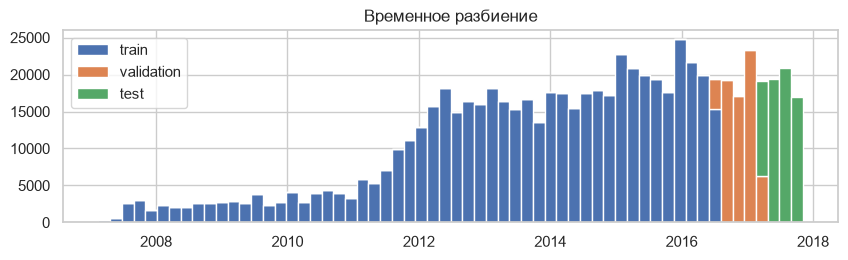

In [5]:
split = common.make_split(inter, books)
val, test = common.make_task(split, "val"), common.make_task(split, "test")

for name, task in (("val", val), ("test", test)):
    out_of_reach = 1 - task.stats["n_rel_kept"] / task.stats["n_rel_total"]
    print(f"[{name}]", *(f"{key}: {value}" for key, value in task.stats.items()), f"Релевантных вне охвата: {out_of_reach:.1%}", "", sep="\n")

plt.figure(figsize=(10, 2.5))
plt.hist([1970 + part.t / common.DAYS_PER_YEAR for part in (split.train, split.val, split.test)], bins=60, stacked=True, label=["train", "validation", "test"])
plt.legend()
plt.title("Временное разбиение")
plt.show()

## 4. Модели

Реализации в `models/`, интерфейс `fit(task)` и `score(users)`; top-10 и метрики в `common.py`.

Обозначения: $X\in\{0,1\}^{U\times I}$ - матрица взаимодействий с оценкой $\ge$ `threshold` (общий порог положительного сигнала: 1 - все оцененные книги, 4 - только понравившиеся), $N_u$ - история пользователя, $n_u=|N_u|$.

Baseline Popularity: самые популярные книги (число оценок >= 4).

### 4.1 ItemKNN

Item-based CF с косинусным расстоянием:

$$ s_{mi}=\frac{\sum_u x_{um}x_{ui}}{\sqrt{d_m\,d_i}},\qquad d_i=\sum_u x_{ui},\qquad r_{um}=\sum_{i\in N_u\cap K_m}s_{mi}, $$

где $K_m$ - $k$ книг с наибольшим $s_{mi}$ (диагональ исключена).

Параметр: $k$

### 4.2 iALS

Предпочтение $p_{ui}=\mathbf 1[x_{ui}>0]$, уверенность $c_{ui}=1+\alpha x_{ui}$ (Hu, Koren, Volinsky, 2008):

$$ \min_{P,Q}\sum_{u,i}c_{ui}\,(p_{ui}-\mathbf p_u^\top\mathbf q_i)^2+\mu\Big(\sum_u\|\mathbf p_u\|^2+\sum_i\|\mathbf q_i\|^2\Big). $$

При фиксированном $Q$ нулевой градиент по $\mathbf p_u$ дает ($C_u=\operatorname{diag}(c_{ui})$)

$$ (Q^\top C_u Q+\mu I)\,\mathbf p_u=Q^\top C_u\,\mathbf p(u)
\ \Longleftrightarrow\ 
\Big(Q^\top Q+\alpha\sum_{i\in N_u}\mathbf q_i\mathbf q_i^\top+\mu I\Big)\mathbf p_u=(1+\alpha)\sum_{i\in N_u}\mathbf q_i. $$

Правая форма использует разреженность: $C_u-I$ ненулевая только на $N_u$, и система строится за $O(|N_u|d^2)$. Для $\mathbf q_i$ уравнение симметричное, решения чередуются.

Параметры: факторы, $\mu$, $\alpha$, итерации

### 4.3 EASE

Линейный автокодировщик (Steck, 2019), $G=X^\top X$:

$$ \min_B\|X-XB\|_F^2+\lambda\|B\|_F^2\quad\text{s.t. }\operatorname{diag}B=0,\qquad (G+\lambda I)B=G-D. $$

Здесь $D$ - диагональ множителей Лагранжа. Для $P=(G+\lambda I)^{-1}$ получаем $B=I-P\tilde D$ с $\tilde D=\lambda I+D$, а условие $B_{jj}=0$ дает $\tilde D_{jj}=1/P_{jj}$:

$$ B_{ij}=-\frac{P_{ij}}{P_{jj}}\ (i\ne j),\qquad B_{jj}=0. $$

Оценка пользователя: $\mathbf x_u B$. Память растет как $I^2$, время как $I^3$, поэтому каталог ограничен подвыборкой. Параметр: $\lambda$

### 4.4 FM с метапризнаками

Строка задается активными токенами $F$: пользователь (id, активность, средняя оценка), книга (id и метаданные), возраст книги на момент $t$:

$$ \hat s=\sum_{f\in F}w_f+\sum_{a<b\in F}\langle\mathbf v_a,\mathbf v_b\rangle
=\sum_{f\in F}w_f+\tfrac12\Big(\big\|\sum_{f\in F}\mathbf v_f\big\|^2-\sum_{f\in F}\|\mathbf v_f\|^2\Big). $$

Обучение по BPR: для положительной пары $(u,i)$ берутся `n_neg` случайных негативов $j$, $\Delta=\hat s(u,i)-\hat s(u,j)$:

$$ \mathcal L=-\log\sigma(\Delta)+\lambda_2\sum_{f\in F}\rho_f\big(\|\mathbf v_f\|^2+w_f^2\big),\qquad
\rho_f=\begin{cases}1,&f\ \text{id-токен}\\ \rho,&f\ \text{метапризнак}\end{cases} $$

Параметр $\rho$ = `meta_reg` усиливает регуляризацию метапризнаков, чтобы общие для многих книг токены не заглушали ID-эмбеддинги.

Для ранжирования делим токены на пользовательские $U$ и книжные $B$: $\mathbf e_u=\sum_{f\in U}\mathbf v_f$, $\mathbf e_i=\sum_{f\in B}\mathbf v_f$. Тогда

$$ \hat s(u,i)=c_u+b_i+\mathbf e_u^\top\mathbf e_i,\qquad
b_i=\sum_{f\in B}w_f+\tfrac12\|\mathbf e_i\|^2-\tfrac12\sum_{f\in B}\|\mathbf v_f\|^2, $$

а $c_u$ не зависит от книги и порядок не меняет. Поэтому ранжируем по $b_i+\mathbf e_u^\top\mathbf e_i$: для всего каталога это одно матричное умножение.

Признаки (только то, что известно в момент рекомендации):

- Пользователь: id, корзина активности $\lfloor\log_2 n_u\rfloor$, корзина средней оценки (шаг 0.5)
- Книга: id, до 3 авторов (редкие: общий токен), год, корзина страниц, format, language, publisher (топ-40), флаги e-book и «в серии», корзина длины описания, 6 ключевых слов (TF-IDF)
- Взаимодействие: возраст книги на момент $t$, $\lfloor\text{year}(t)\rfloor-\text{publication\_year}$ (при рекомендации: на начало окна)

Агрегаты по всему периоду (`average_rating`, `popular_shelves` и др.) не используются.

### 4.5 timeSVD++

Предсказывает оценку пользователя. Сначала SVD++: средняя оценка $\mu$, склонности пользователя $b_u$ и книги $b_i$, совпадение вкусов $\mathbf p_u$ с характеристиками книги $\mathbf q_i$. Вектор $\mathbf z_u=|N_u|^{-1/2}\sum_{j\in N_u}\mathbf y_j$ учитывает, какие книги пользователь уже оценивал:

$$ \hat r_{ui}=\mu+b_u+b_i+\mathbf q_i^\top(\mathbf p_u+\mathbf z_u). $$

Добавляем время: $\mathrm{dev}_u(t)$ - насколько момент $t$ отстоит от среднего времени оценок пользователя $t_u$ (в годах). Склонность и вкусы пользователя сдвигаются вместе с ним, а качество книги зависит от периода ($\mathrm{Bin}(t)$ - один из `n_bins` периодов):

$$ \mathrm{dev}_u(t)=\operatorname{sign}(t-t_u)\,|t-t_u|^{\beta},\qquad
\hat r_{ui}(t)=\mu+b_u+a_u\,\mathrm{dev}_u(t)+b_i+b_{i,\mathrm{Bin}(t)}+\mathbf q_i^\top\big(\mathbf p_u+\mathbf a_u\,\mathrm{dev}_u(t)+\mathbf z_u\big). $$

Обучение: предсказанные оценки приближают настоящие (MSE, штраф на параметры, Adam).

В рекомендациях берется момент $T$, слагаемые только про пользователя отбрасываются: на выбор книг они не влияют. Чтобы не выбирать редкие книги с высокой оценкой, добавляется популярность $\widehat{\mathrm{logpop}}_i$ (логарифм числа оценок) с весом $\rho$ = `pop_blend`:

$$ s(u,i)=b_i+b_{i,\mathrm{Bin}(T)}+\mathbf q_i^\top\big(\mathbf p_u+\mathbf a_u\mathrm{dev}_u(T)+\mathbf z_u\big)+\rho\,\widehat{\mathrm{logpop}}_i. $$

Для сравнения: SVD++ (без времени) и $\rho=0$.

## 5. Подбор гиперпараметров на validation

Optuna TPE, MedianPruner для итеративных моделей, выбор по NDCG@10 на validation, число эпох как лучшая эпоха на validation. Результаты кэшируются в `results/best_params.json`. Общий для моделей на взаимодействиях параметр: threshold $\in \{1, 4\}$.

In [6]:
SPACES = {
    "ItemKNN": {
        "k": {"type": "int", "range": [3, 300], "log": True},
        "threshold": {"type": "cat", "values": [1, 4]},
    },
    "EASE": {
        "lam": {"type": "float", "range": [10, 10000], "log": True},
        "threshold": {"type": "cat", "values": [1, 4]},
    },
    "iALS": {
        "factors": {"type": "cat", "values": [32, 64, 96, 128]},
        "reg": {"type": "float", "range": [0.01, 300], "log": True},
        "alpha": {"type": "float", "range": [1, 100], "log": True},
        "threshold": {"type": "cat", "values": [1, 4]},
    },
    "FM (ID only)": {
        "dim": {"type": "cat", "values": [16, 32, 64]},
        "lr": {"type": "float", "range": [1e-3, 2e-2], "log": True},
        "l2": {"type": "float", "range": [1e-6, 1e-2], "log": True},
        "n_neg": {"type": "cat", "values": [1, 2, 4]},
        "threshold": {"type": "cat", "values": [1, 4]},
    },
    "timeSVD++": {
        "factors": {"type": "cat", "values": [8, 16, 32, 64]},
        "lr": {"type": "float", "range": [3e-3, 3e-2], "log": True},
        "reg": {"type": "float", "range": [1e-3, 1], "log": True},
        "beta": {"type": "float", "range": [0.2, 0.6]},
        "n_bins": {"type": "cat", "values": [5, 10, 20]},
        "pop_blend": {"type": "cat", "values": [0.0, 0.25, 0.5, 1.0, 2.0]},
    },
}
SPACES["FM (meta)"] = {**SPACES["FM (ID only)"], "meta_reg": {"type": "float", "range": [0.1, 100], "log": True}}

In [7]:
FM_START_ID = [dict(dim=32, lr=5e-3, l2=1e-4, n_neg=2, threshold=4), dict(dim=64, lr=3e-3, l2=1.3e-5, n_neg=4, threshold=4)]
FM_START_META = [dict(params, meta_reg=1.0) for params in FM_START_ID]

SPECS = {
    "ItemKNN": dict(build=lambda p: ItemKNN(**p), space=SPACES["ItemKNN"], n_trials=20),
    "EASE": dict(build=lambda p: EASE(**p), space=SPACES["EASE"], n_trials=12),
    "iALS": dict(build=lambda p: IALS(**p), space=SPACES["iALS"], n_trials=20, iterative=True, max_epochs=20),
    "FM (meta)": dict(build=lambda p: FM(use_meta=True, **p), space=SPACES["FM (meta)"], n_trials=16, iterative=True, max_epochs=40, eval_every=2, warm_start=FM_START_META),
    "FM (ID only)": dict(build=lambda p: FM(use_meta=False, **p), space=SPACES["FM (ID only)"], n_trials=16, iterative=True, max_epochs=40, eval_every=2, warm_start=FM_START_ID),
    "timeSVD++": dict(build=lambda p: TimeSVDpp(**p), space=SPACES["timeSVD++"], n_trials=20, iterative=True, max_epochs=30),
}

best = json.loads(CACHE.read_text()) if CACHE.exists() else {}

for name, spec in SPECS.items():
    if name in best:
        continue

    study, params = tuning.search(task=val, **spec)
    best[name] = dict(params=params, val_ndcg=study.best_value, n_trials=len(study.trials))
    CACHE.write_text(json.dumps(best, indent=1))

pd.DataFrame({name: {**b["params"], "val NDCG@10": round(b["val_ndcg"], 4)} for name, b in best.items()}).T

,k,threshold,val NDCG@10,lam,factors,reg,alpha,epochs,lr,beta,n_bins,pop_blend,dim,l2,n_neg,meta_reg
ItemKNN,5.0,4.0,0.1123,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EASE,NaN,4.0,0.1106,91.037103,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
iALS,NaN,4.0,0.0988,NaN,128.0,0.106293,4.34144,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timeSVD++,NaN,NaN,0.0582,NaN,16.0,0.003297,NaN,1.0,0.006754,0.448462,5.0,0.25,NaN,NaN,NaN,NaN
FM (meta),NaN,4.0,0.0791,NaN,NaN,NaN,NaN,24.0,0.003000,NaN,NaN,NaN,64.0,0.000013,4.0,1.0
FM (ID only),NaN,4.0,0.0816,NaN,NaN,NaN,NaN,16.0,0.003662,NaN,NaN,NaN,64.0,0.000035,4.0,NaN


## 6. Финальное сравнение на test

Лучшие параметры с validation, переобучение на train + validation. Стохастические модели: 3 сида (42, 43, 44), среднее ± std. Строки с дефисом - абляции.

In [8]:
SEEDS = [42, 43, 44]
FAMILIES = {
    "Popularity": Popularity,
    "ItemKNN": ItemKNN,
    "EASE": EASE,
    "iALS": IALS,
    "FM (meta)": partial(FM, use_meta=True),
    "FM (ID only)": partial(FM, use_meta=False),
    "timeSVD++": TimeSVDpp,
    "SVD++": TimeSVDpp,
}
STOCHASTIC = {"iALS", "FM (meta)", "FM (ID only)", "timeSVD++", "SVD++"}

tsvd = best["timeSVD++"]["params"]
CONFIGS = {
    "Popularity": ("Popularity", {}),
    "ItemKNN": ("ItemKNN", best["ItemKNN"]["params"]),
    "iALS": ("iALS", best["iALS"]["params"]),
    "EASE": ("EASE", best["EASE"]["params"]),
    "FM (meta)": ("FM (meta)", best["FM (meta)"]["params"]),
    "timeSVD++": ("timeSVD++", tsvd),
    "- FM (ID only)": ("FM (ID only)", best["FM (ID only)"]["params"]),
    "- SVD++ (без времени)": ("SVD++", {**tsvd, "use_time": False}),
    "- timeSVD++ (pop_blend=0)": ("timeSVD++", {**tsvd, "pop_blend": 0.0}),
}

runs = {}

for label, (family, params) in CONFIGS.items():
    stochastic = family in STOCHASTIC
    runs[label] = []

    for seed in SEEDS if stochastic else [SEED]:
        common.set_seed(seed)
        model = FAMILIES[family](**params, **({"seed": seed} if stochastic else {}))
        runs[label].append(common.run(model, test))

    print(f"{label}, NDCG@10: {np.mean([r[0]['NDCG@10'] for r in runs[label]]):.4f}")

Popularity, NDCG@10: 0.0424


ItemKNN, NDCG@10: 0.0978


iALS, NDCG@10: 0.0898


EASE, NDCG@10: 0.1019


FM (meta), NDCG@10: 0.0730


timeSVD++, NDCG@10: 0.0482


- FM (ID only), NDCG@10: 0.0734


- SVD++ (без времени), NDCG@10: 0.0486


- timeSVD++ (pop_blend=0), NDCG@10: 0.0119


In [9]:
METRICS = ["NDCG@10", "Recall@10", "MAP@10", "HitRate@10", "Coverage@10"]
rows = {}

for label, out in runs.items():
    metrics = pd.DataFrame([r[0] for r in out])
    low, high = common.bootstrap_ci(out[0][1]["NDCG@10"])
    rows[label] = {m: f"{metrics[m].mean():.4f}" + (f" ± {metrics[m].std(ddof=0):.4f}" if len(out) > 1 else "") for m in METRICS}
    rows[label]["NDCG@10 95% CI"] = f"[{low:.4f}, {high:.4f}]"

pd.DataFrame(rows).T

,NDCG@10,Recall@10,MAP@10,HitRate@10,Coverage@10,NDCG@10 95% CI
Popularity,0.0424,0.0430,0.0240,0.1400,0.0050,"[0.0388, 0.0456]"
ItemKNN,0.0978,0.1055,0.0613,0.2907,0.6934,"[0.0926, 0.1034]"
iALS,0.0898 ± 0.0006,0.0939 ± 0.0003,0.0570 ± 0.0008,0.2647 ± 0.0008,0.3420 ± 0.0018,"[0.0853, 0.0960]"
EASE,0.1019,0.1099,0.0624,0.3164,0.5233,"[0.0965, 0.1073]"
FM (meta),0.0730 ± 0.0019,0.0834 ± 0.0013,0.0408 ± 0.0016,0.2647 ± 0.0014,0.2952 ± 0.0126,"[0.0666, 0.0746]"
timeSVD++,0.0482 ± 0.0019,0.0497 ± 0.0016,0.0286 ± 0.0012,0.1539 ± 0.0063,0.0116 ± 0.0005,"[0.0453, 0.0530]"
- FM (ID only),0.0734 ± 0.0003,0.0785 ± 0.0004,0.0435 ± 0.0002,0.2421 ± 0.0012,0.4577 ± 0.0028,"[0.0693, 0.0785]"
- SVD++ (без времени),0.0486 ± 0.0020,0.0510 ± 0.0021,0.0284 ± 0.0012,0.1571 ± 0.0061,0.0125 ± 0.0004,"[0.0463, 0.0540]"
- timeSVD++ (pop_blend=0),0.0119 ± 0.0003,0.0133 ± 0.0007,0.0062 ± 0.0004,0.0540 ± 0.0010,0.0472 ± 0.0017,"[0.0100, 0.0133]"


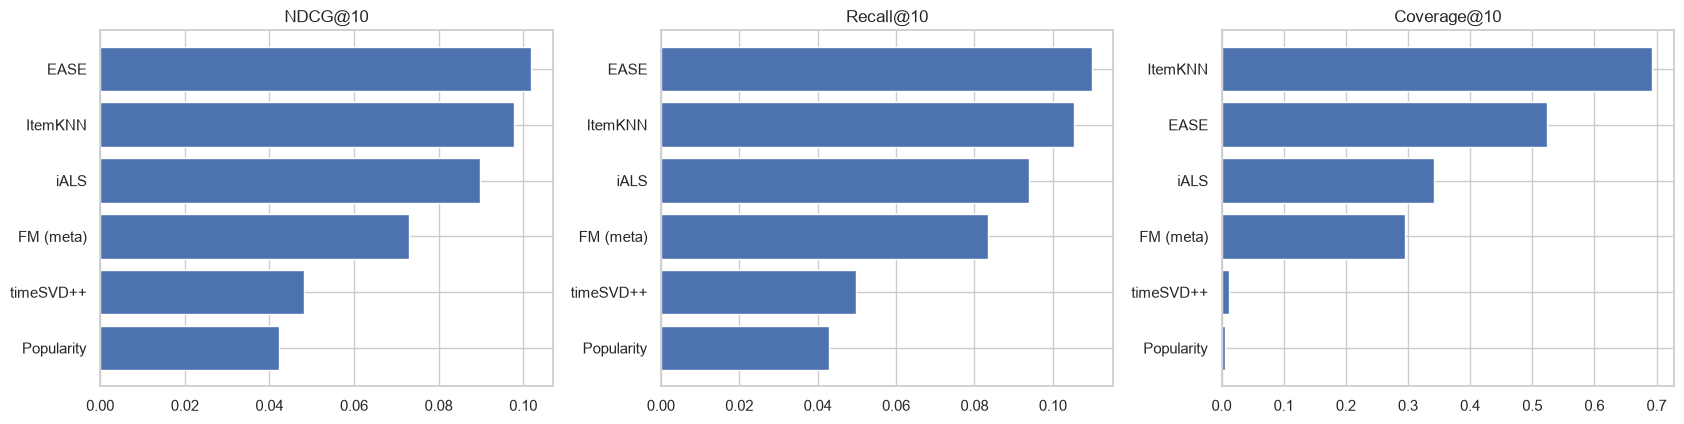

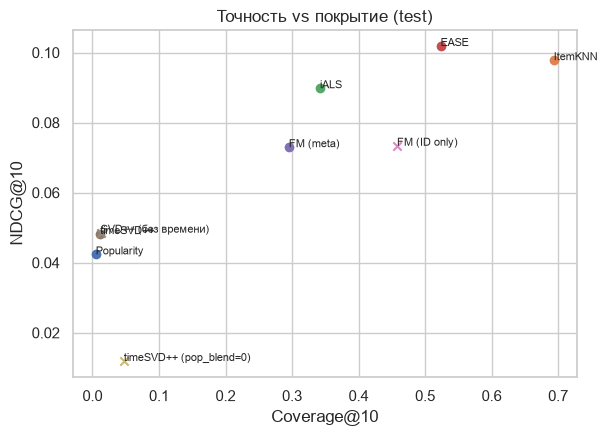

In [10]:
means = pd.DataFrame({label: pd.DataFrame([r[0] for r in out]).mean() for label, out in runs.items()}).T
main = [label for label in means.index if not label.startswith("-")]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
for a, metric in zip(ax, ["NDCG@10", "Recall@10", "Coverage@10"]):
    s = means.loc[main, metric].sort_values()
    a.barh(s.index, s.values)
    a.set_title(metric)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for label, row in means.iterrows():
    ax.scatter(row["Coverage@10"], row["NDCG@10"], marker="o" if label in main else "x")
    ax.annotate(label.strip("- "), (row["Coverage@10"], row["NDCG@10"]), fontsize=8)
ax.set(xlabel="Coverage@10", ylabel="NDCG@10", title="Точность vs покрытие (test)")
plt.show()

### Надежна ли разница между моделями?

Парный bootstrap по пользователям: разница NDCG@10 лучшей модели с каждой другой на одних и тех же пользователях.

In [11]:
# paired bootstrap of the NDCG@10 difference between the best model and the others (same users)
best_label = means.loc[main, "NDCG@10"].idxmax()
best_ndcg = runs[best_label][0][1]["NDCG@10"]
n_eval = len(test.eval_users)
idx = np.random.default_rng(SEED).integers(0, n_eval, size=(common.BOOTSTRAP_ROUNDS, n_eval))

rows = []
for label in main:
    if label == best_label:
        continue

    diff = best_ndcg - runs[label][0][1]["NDCG@10"]
    low, high = np.quantile(diff[idx].mean(1), [common.CI_ALPHA / 2, 1 - common.CI_ALPHA / 2])
    rows.append({"против": label, f"ΔNDCG@10 ({best_label} - модель)": diff.mean(), "95% CI": f"[{low:.4f}, {high:.4f}]", "значимо": low > 0})

pd.DataFrame(rows).set_index("против").round(4)

,ΔNDCG@10 (EASE - модель),95% CI,значимо
против,,,
Popularity,0.0595,"[0.0538, 0.0654]",True
ItemKNN,0.0040,"[0.0008, 0.0072]",True
iALS,0.0113,"[0.0084, 0.0141]",True
FM (meta),0.0313,"[0.0262, 0.0365]",True
timeSVD++,0.0527,"[0.0470, 0.0585]",True


### Кому помогают модели

NDCG@10 по длине истории пользователя, справа средняя популярность рекомендованных книг.

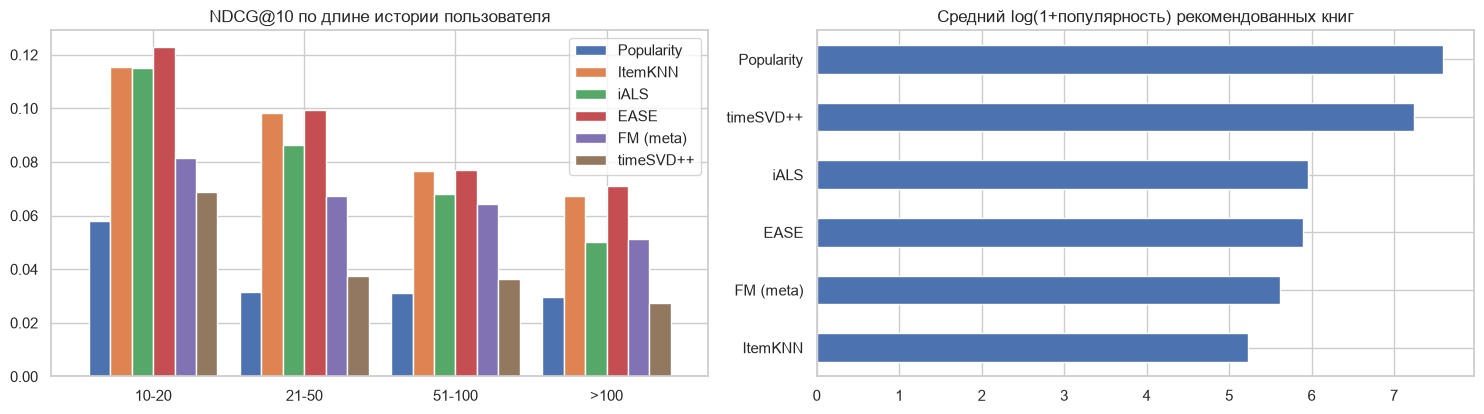

In [12]:
HISTORY_EDGES = [0, 20, 50, 100, np.inf]
history = np.asarray(test.seen.sum(1)).ravel()[test.eval_users]
groups = pd.cut(history, HISTORY_EDGES, labels=["10-20", "21-50", "51-100", ">100"])
by_history = pd.DataFrame({label: pd.Series(runs[label][0][1]["NDCG@10"]).groupby(groups).mean() for label in main})

popularity = np.asarray(test.seen.sum(0)).ravel()
rec_popularity = pd.Series({label: np.log1p(popularity[runs[label][0][2]]).mean() for label in main}).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
by_history.plot.bar(ax=ax[0], width=0.85, rot=0, title="NDCG@10 по длине истории пользователя")
rec_popularity.plot.barh(ax=ax[1], title="Средний log(1+популярность) рекомендованных книг")
plt.tight_layout()
plt.show()

### Временные компоненты timeSVD++

Лучший NDCG@10 достигается после 1 эпохи, поэтому сравниваем timeSVD++ и SVD++ по RMSE рейтингов по эпохам. Эпоха для test выбрана по validation RMSE.

Константный предсказатель, test RMSE: 0.8871


,эпоха (по val RMSE),val RMSE,test RMSE,val NDCG@10 (эта эпоха),лучший val NDCG@10
модель,,,,,
timeSVD++,2,0.8034,0.7981,0.0503,0.0582
SVD++,3,0.7971,0.7858,0.0494,0.0574


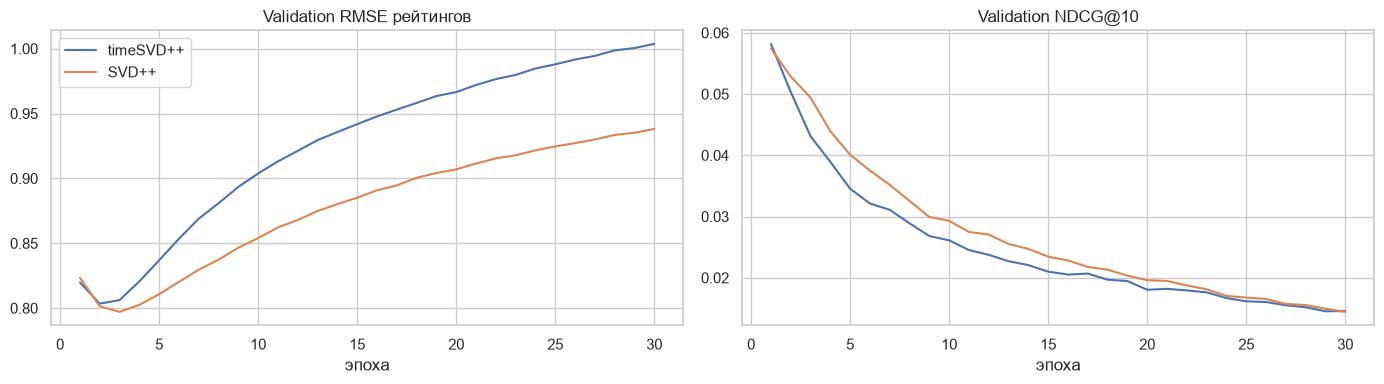

In [13]:
MAX_EPOCHS = 30


def warm_rows(task):
    target = task.target_df
    has_history = np.asarray(task.seen.sum(1)).ravel() > 0
    return target[task.candidate_mask[target.i.values] & has_history[target.u.values]]


curves, rows = {}, []

for use_time in (True, False):
    log = []

    def track(model, epoch):
        ndcg = common.evaluate(common.recommend(model, val), val)[0]["NDCG@10"]
        log.append((epoch, model.rmse(warm_rows(val)), ndcg))
        return False

    TimeSVDpp(**{**tsvd, "use_time": use_time, "epochs": MAX_EPOCHS}).fit(val, on_epoch=track)
    curve = pd.DataFrame(log, columns=["epoch", "val_rmse", "val_ndcg"])
    epoch = int(curve.loc[curve.val_rmse.idxmin(), "epoch"])

    common.set_seed(SEED)
    model = TimeSVDpp(**{**tsvd, "use_time": use_time, "epochs": epoch}).fit(test)

    curves[use_time] = curve
    rows.append({
        "модель": "timeSVD++" if use_time else "SVD++",
        "эпоха (по val RMSE)": epoch,
        "val RMSE": curve.val_rmse.min(),
        "test RMSE": model.rmse(warm_rows(test)),
        "val NDCG@10 (эта эпоха)": curve.loc[curve.epoch == epoch, "val_ndcg"].iloc[0],
        "лучший val NDCG@10": curve.val_ndcg.max(),
    })

mean_rating = test.fit_df.rating.mean()
print(f"Константный предсказатель, test RMSE: {np.sqrt(((warm_rows(test).rating - mean_rating) ** 2).mean()):.4f}")
display(pd.DataFrame(rows).set_index("модель").round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for use_time, curve in curves.items():
    label = "timeSVD++" if use_time else "SVD++"
    ax[0].plot(curve.epoch, curve.val_rmse, label=label)
    ax[1].plot(curve.epoch, curve.val_ndcg, label=label)
ax[0].set(title="Validation RMSE рейтингов", xlabel="эпоха")
ax[1].set(title="Validation NDCG@10", xlabel="эпоха")
ax[0].legend()
plt.tight_layout()
plt.show()

### Пример рекомендаций

Последние оценки одного пользователя и выдача лучшей модели.

In [14]:
titles = split.books.title.values
recs = runs[best_label][0][2]
hits = test.rel[np.arange(len(recs))[:, None], recs].sum(1)
position = int(np.argmax(hits >= 2))
user = test.eval_users[position]

recent = test.fit_df[test.fit_df.u == user].sort_values("t").tail(5)
print("Последние оценки пользователя:", *(f"{titles[i]}: {r}" for i, r in zip(recent.i, recent.rating)), "", sep="\n")
print(f"Рекомендации {best_label}:", *(f"{titles[i]}{' (релевантна)' if test.rel[position, i] else ''}" for i in recs[position]), sep="\n")

Последние оценки пользователя:
Scott Pilgrim, Volume 6: Scott Pilgrim's Finest Hour: 5
Scott Pilgrim, Volume 2: Scott Pilgrim vs. The World: 5
Saga, Vol. 1 (Saga, #1): 5

Рекомендации EASE:
Scott Pilgrim, Volume 1: Scott Pilgrim's Precious Little Life
Scott Pilgrim, Volume 3: Scott Pilgrim & The Infinite Sadness
Scott Pilgrim, Volume 5: Scott Pilgrim Vs. the Universe
Scott Pilgrim, Volume 4: Scott Pilgrim Gets It Together
Saga, Vol. 2 (Saga, #2) (релевантна)
Kick-Ass (Kick-Ass, #1)
Saga, Vol. 3 (Saga, #3)
Seconds (релевантна)
Hyperbole and a Half: Unfortunate Situations, Flawed Coping Mechanisms, Mayhem, and Other Things That Happened
Lost at Sea (релевантна)


## 7. Выводы

Топ моделей по метрике NDCG@10:
EASE 0.1019
ItemKNN 0.0978
iALS 0.0898
FM 0.0730
timeSVD++ 0.0482
Popularity 0.0424

В данной задаче модель EASE оказалась статзначимо лучше других, потому что у модели всего один гиперпараметр, что позволяет модели не переобучаться. Также на датасете такого размера плотная матрица помещается в память и решается точно, чем EASE выигрывает у итеративной iALS.

ItemKNN на validation лучше, а на test хуже, потому что опирается на 5 ближайших соседей. Такая модель сильно зависит от того, какие пары книг встречаются в конкретном окне, а гиперпараметры подбирались именно на validation. Итого ItemKNN потерял около 13%, EASE около 8% на test относительно validation.

FM с метаданными показала себя плохо, потому что кандидаты это книги не менее чем с 20 оценками, их ID уже хорошо обучены, а польза метаданных в cold-start, который мы не оцениваем. NDCG@10 с метаданными 0.0730, без них 0.0734.

timeSVD++ показала себя плохо, потому что учится предсказывать оценку, а оценивается по top-10. Добавка популярности поднимает NDCG@10 с 0.0119 до 0.0482, а временные компоненты не помогают: SVD++ без времени дает 0.0486.

Главные ограничения эксперимента: один датасет, одно временное разбиение и одно test-окно, поэтому порядок моделей на других данных мог бы быть другим. Также мы не измеряли cold start, поэтому результаты показывают качество рекомендаций только для пользователей с историей и уже известных книг.